# A 3D coil on a cyclic sector

This notebook follows `tests/coil_3D_avoltemf`: the coil and the passive ring of the 2D examples, now in 3D, modelled
on a **30 degree sector** about the y axis with cyclic symmetry. It shows:

* selections in a cylindrical coordinate system, and far-field / axis conditions on a nodal vector potential;
* an **element coordinate system** in which the winding direction of the coil is simply `T = (0, 1, 0)` (toroidal);
* **cyclic symmetry**: `periodic_boundaries()` pairs the nodes of the two sector faces, and the nodal frames of one
  face are rotated (`node_angles`) so that the same cylindrical components are coupled;
* the `symmetry` real constant: the loads refer to the whole coil although only 1/12 is modelled;
* the eddy currents of the passive ring after a current step, and 3D views of the full ring with pyvista.

See the user manual (*DOF Couplings and Periodic Boundaries*, *Coordinate Systems*, *Boundary Conditions*).

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../tests/coil_3D_avoltemf").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_coil_3D_avoltemf_"))
for name in ("coil_3D_avoltemf.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

working in a temporary folder: pytec3d_coil_3D_avoltemf_b1ctoejh


## Model and boundary conditions

The coil (TYPE 23, `STRANDED_COIL`, 2000 turns) at r = 0.5 m, y = -0.5 m; the passive ring (TYPE 24,
`SOLID_CONDUCTOR`, with the electric potential V) at y = +0.5 m. In the Y-axis cylindrical system,
coordinate 0 is r, 1 is theta (degrees, from +x towards -z), 2 is the axial coordinate y.

In [2]:
from pytec3d import YAxisCylindricalCoordinateSystem
cyl = YAxisCylindricalCoordinateSystem()
tol = 1e-5

solver = Solver()
solver.read_model("coil_3D_avoltemf.vtu")
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
print(solver.model, "- coil constants:", solver.model.data["constants"]["1"])

# far field: A = 0 on y = +-1 and r = 1
selection.select_pos(mesh, 2, (1 - tol, 1 + tol), coordinate_system=cyl)
selection.select_pos(mesh, 2, (-1 - tol, -1 + tol), mode="a", coordinate_system=cyl)
selection.select_pos(mesh, 0, (1 - tol, 1 + tol), mode="a", coordinate_system=cyl)
for c in (0, 1, 2):
    selection.set_value_on_selection(mesh, "_A", 0.0, c)
# axis r = 0: the components normal to the axis vanish
selection.select_pos(mesh, 0, (-tol, tol), coordinate_system=cyl)
selection.set_value_on_selection(mesh, "_A", 0.0, 0)
selection.set_value_on_selection(mesh, "_A", 0.0, 2)

Model('coil_3D_avoltemf', 4961 points, 4000 cells) - coil constants: {'thickness': 1.0, 'cross_section': 0.04, 'turns': 2000.0, 'volume': 0.12566370614359, 'resistance': 20.0, 'symmetry': 12.0, 'T': [0.0, 1.0, 0.0]}


## Coil terminal, element coordinate system, cyclic symmetry

The coil cells use the cylindrical system 1, so `T = (0, 1, 0)` of the real constants is the toroidal direction in
every cell. Its nodes share one `VOLT` and one `EMF` (CP id 1). The nodes of the face theta = 0 are paired with their
images at theta = 30 degrees in a fresh array `CP_1`, coupling A and V.

In [3]:
import vtk
solver.model.set_coordinate_system(1, cyl)
selection.select(mesh, "MATERIAL", 23, location="elem")
selection.set_value_on_selection(mesh, "COORDINATE_SYSTEM", 1, location="elem")
selection.nsle(mesh)
selection.set_value_on_selection(mesh, "CP_0", 1)
master = int(selection.selected_ids(mesh, "node")[0])

meshes.remove_array(mesh, "CP_1")
meshes.add_array(mesh, "CP_1", dtype=vtk.VTK_INT)
selection.select_pos(mesh, 1, (-tol, tol), coordinate_system=cyl)
pairs = solver.model.periodic_boundaries(cyl, ("A", "V"), dy=30.0, array_name="CP_1")
selection.select_pos(mesh, 1, (30 - tol, 30 + tol), coordinate_system=cyl)
selection.set_value_on_selection(mesh, "node_angles", 30.0, 2)
print(len(pairs), "periodic pairs")

# the potential of the passive ring floats: fix it on one of its nodes
selection.select(mesh, "MATERIAL", 24, location="elem"); selection.nsle(mesh)
selection.select(mesh, "ID", int(selection.selected_ids(mesh, "node")[0]))
selection.set_value_on_selection(mesh, "_V", 0.0)

820 periodic pairs


## A current step

The coil current jumps from 0 to 100 A at t = 0 (`CURR` on the master node; it is the current of the whole coil) and
is kept constant; backward Euler, 10 steps of 5 ms. The passive ring reacts with an eddy current that opposes the
change of flux and then decays with the L/R time of the ring. We estimate the ring current from the element current
density: the toroidal component of `Jt`, integrated over the sector and divided by the sector length (its mean over
the 30 degrees).

In [4]:
with quietly():
    solver.load_model_into_solver()
solver.time_step["theta"] = 1.0
selection.select(mesh, "ID", master)
selection.set_value_on_selection(mesh, "CURR", 100.0)

centroids = meshes.array_values(mesh, "cell_centroids", "elem")
volume = meshes.array_values(mesh, "cell_volume", "elem")
ring_cells = meshes.array_values(mesh, "MATERIAL", "elem") == 24
local = cyl.to_local(centroids[ring_cells])
rows = []
for n in range(1, 11):
    solver.time_step["time"] = n * 5e-3
    solver.solve()
    jt = meshes.array_values(mesh, "Jt", "elem")[ring_cells]
    j_theta = cyl.vector_components_to_local(jt, centroids[ring_cells])[:, 1]
    i_ring = np.sum(j_theta * volume[ring_cells] / (local[:, 0] * np.deg2rad(30.0)))
    volt = meshes.array_values(mesh, "VOLT", "node")[master]
    emf = meshes.array_values(mesh, "EMF", "node")[master]
    rows.append((n * 5e-3, volt, emf, i_ring))
solver.write_output()
rows = np.array(rows)
print("  t [ms]   VOLT [V]   EMF [V]   I ring [A]")
for t, v, e, i in rows:
    print(f"  {t * 1e3:5.0f}   {v:8.2f}   {e:8.2f}   {i:9.2f}")

  t [ms]   VOLT [V]   EMF [V]   I ring [A]
      5   81671.66   79668.00    -5063.31
     10    2006.48       2.81    -4905.11
     15    2005.89       2.23    -4778.52
     20    2005.51       1.85    -4672.38
     25    2005.24       1.58    -4580.50
     30    2005.04       1.38    -4499.16
     35    2004.88       1.22    -4425.93
     40    2004.76       1.10    -4359.14
     45    2004.66       1.00    -4297.59
     50    2004.58       0.92    -4240.37


With the current imposed, the terminal voltage is `VOLT = R i + EMF`. At the first step the current jumps from 0 to
100 A in 5 ms: the EMF `L di/dt` (about 80 kV, L of the order of 4 H) dominates. Afterwards the current is constant and
`VOLT` is `R i = 2000 V` plus the small voltage induced by the decaying eddy current of the ring.

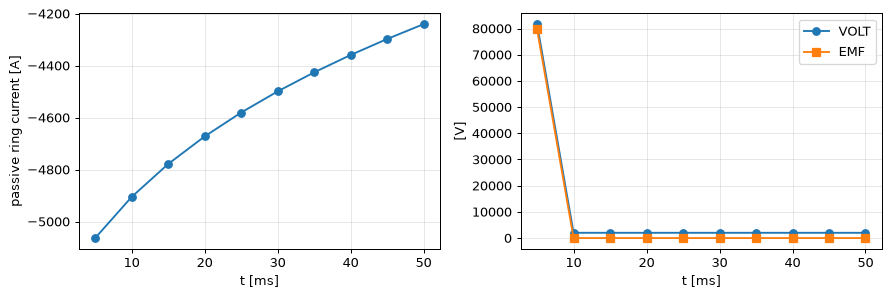

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(rows[:, 0] * 1e3, rows[:, 3], "o-"); ax[0].set_ylabel("passive ring current [A]")
ax[1].plot(rows[:, 0] * 1e3, rows[:, 1], "o-", label="VOLT"); ax[1].plot(rows[:, 0] * 1e3, rows[:, 2], "s-", label="EMF")
ax[1].set_ylabel("[V]"); ax[1].legend()
for a in ax:
    a.set_xlabel("t [ms]"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## The full ring in 3D

pyvista reads the VTK grid directly. The sector is copied 12 times, rotated about the y axis, to show the whole
machine: the coil (copper colour), the passive ring coloured by its toroidal eddy current density (opposite to the
coil current), and |B| on the face theta = 0.

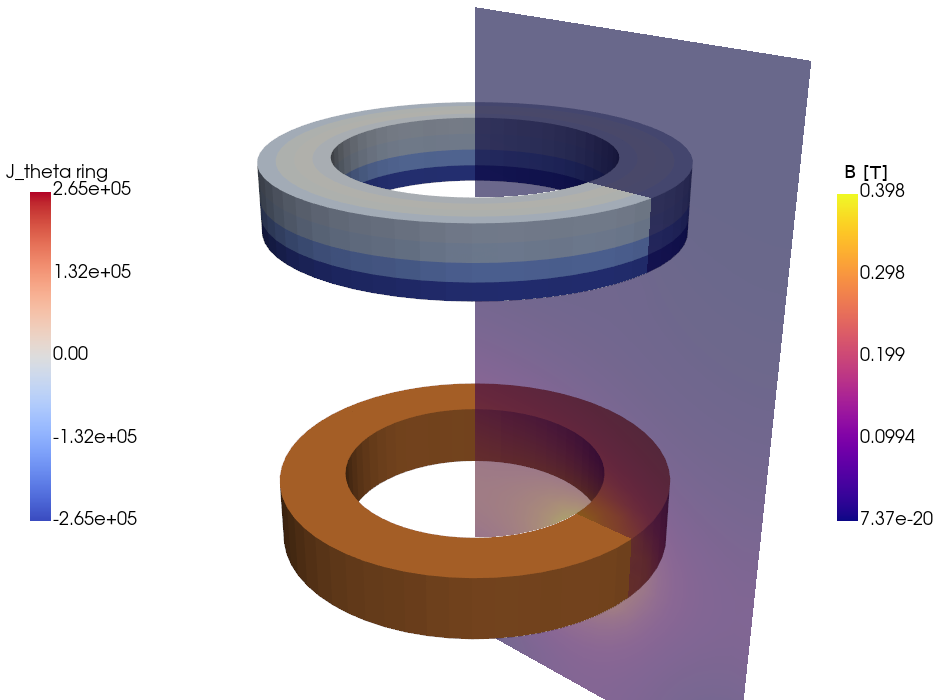

In [6]:
grid = pv.wrap(mesh).copy()
jt = grid.cell_data["Jt"]
grid.cell_data["J_theta"] = cyl.vector_components_to_local(jt, grid.cell_centers().points)[:, 1]
grid.point_data["|B|"] = np.linalg.norm(grid.point_data["B"], axis=1)
coil = grid.threshold(value=(23, 23), scalars="TYPE")
ring = grid.threshold(value=(24, 24), scalars="TYPE")
face = grid.slice(normal=(0, 0, 1), origin=(0, 0, -1e-6))          # the plane z = 0 (theta = 0)
limit = np.abs(ring["J_theta"]).max()

pl = pv.Plotter(window_size=(950, 700))
for k in range(12):
    pl.add_mesh(coil.rotate_y(30.0 * k, inplace=False), color="#c87533")
    pl.add_mesh(ring.rotate_y(30.0 * k, inplace=False), scalars="J_theta", cmap="coolwarm", clim=[-limit, limit],
                show_scalar_bar=(k == 0), scalar_bar_args={"title": "J_theta ring", "vertical": True, "position_x": 0.03, "position_y": 0.25, "height": 0.5, "width": 0.06})
pl.add_mesh(face, scalars="|B|", cmap="plasma", opacity=0.6, scalar_bar_args={"title": "|B| [T]", "vertical": True, "position_x": 0.88, "position_y": 0.25, "height": 0.5, "width": 0.06})
pl.camera_position = [(2.4, 1.6, 2.6), (0, 0, 0), (0, 1, 0)]
pl.show()
with quietly():
    solver.close()

## Try it yourself

* Drive the coil by a voltage (`_VOLT` on the master node, `CURR = 0`) and plot the coil current
  `(VOLT - EMF) / R`.
* Remove the frame rotation (`node_angles`) and compare: the periodic coupling then ties the global x and z components
  of the two faces, which is wrong for a rotated sector.
* Run the edge-element version (`tests/coil_3D_avoltemf_edge`): no frame rotation is needed, a tree-cotree gauge is.